# Bab 8 - Mempelajari Sinyal dan Mengabaikan Noise: Regularisasi dan Batching

**Buku:** *Grokking Deep Learning* (Andrew W. Trask, Manning)

## Ringkasan bab
Sekarang kita melatih jaringan tiga layer pada data angka tulisan tangan **MNIST** dan mempelajari apa yang terjadi ketika jaringan belajar *terlalu banyak*.

1. **Jaringan tiga layer pada MNIST:** 784 piksel -> hidden layer (ReLU) -> 10 output; dilatih dengan 1.000 gambar pertama, diuji pada 10.000 gambar uji.
2. **Overfitting:** jaringan mencapai akurasi ~100% pada gambar pelatihan, namun akurasinya pada gambar uji berhenti meningkat atau justru semakin *memburuk*. Jaringan telah **menghafal** set pelatihan (termasuk noise-nya), alih-alih mempelajari pola umumnya.
3. **Mengapa hal ini terjadi:** model dengan banyak bobot dan data yang sedikit dapat menyesuaikan diri secara berlebihan pada detail setiap contoh. Error pada data pelatihan terus menurun, sementara error pada data baru yang belum pernah dilihat mulai meningkat.
4. **Metode Regularisasi** untuk mengatasi overfitting:
   * **Early stopping** - menghentikan pelatihan ketika error uji (validasi) mulai naik.
   * **Dropout** - mematikan separuh node hidden secara acak selama pelatihan.
   * **Batch (mini-batch) gradient descent** - merata-ratakan pembaruan bobot pada beberapa contoh sekaligus.
5. **Dropout** bekerja seperti melatih banyak jaringan kecil yang berbeda lalu merata-ratakannya (sebuah *ensemble*).
6. **Batching** mempercepat pelatihan (operasi matriks pada banyak contoh sekaligus) sekaligus menghaluskan pembaruan yang ber-noise.

## Teori secara mendalam
* **Overfitting** adalah masalah praktis utama dalam machine learning: tujuannya adalah berkinerja baik pada data **baru**, bukan hanya pada data pelatihan. Oleh karena itu, kita harus mengukur kinerja pada set **uji (validasi)** terpisah yang tidak pernah dilihat oleh jaringan saat pelatihan.
* **Noise vs. sinyal:** setiap gambar pelatihan mengandung *sinyal* (bentuk digit yang dapat digeneralisasi) dan *noise* (keanehan/kekhasan dari gambar spesifik tersebut). Jaringan besar dengan hanya 1.000 contoh dapat menemukan bobot yang juga menjelaskan noise tersebut.
* **Early stopping:** metode regularisasi paling sederhana. Pantau error pada data evaluasi dan berhentilah pada titik terbaik.
* **Dropout:** selama pelatihan, setiap node hidden dinonaktifkan dengan probabilitas 0.5 dan node yang tersisa dikalikan dengan 2 agar total sinyal yang diharapkan tetap sama. Suatu node tidak dapat bergantung pada keberadaan tetangganya, sehingga node tersebut harus bermanfaat *secara mandiri*, yang mencegah *ko-adaptasi* (kelompok node yang menghafal bersama-sama). Pada saat evaluasi/pengujian, dropout **tidak** diterapkan.
* **Mini-batch gradient descent:** hitung rata-rata gradien untuk misalnya 100 contoh dan perbarui bobot satu kali. Rata-rata ini merupakan estimasi gradien sebenarnya yang lebih minim noise, dan pembaruan memanfaatkan operasi matriks yang cepat. Contoh individual dengan noise yang tidak lazim menjadi kurang berpengaruh.


In [1]:
import gzip
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

DATA = Path('..') / 'data' / 'mnist'

def load_images(name):
    with gzip.open(DATA / name, 'rb') as fh:
        return np.frombuffer(fh.read(), np.uint8, offset=16).reshape(-1, 28 * 28)

def load_labels(name):
    with gzip.open(DATA / name, 'rb') as fh:
        return np.frombuffer(fh.read(), np.uint8, offset=8)

def one_hot(labels, n=10):
    out = np.zeros((len(labels), n))
    out[np.arange(len(labels)), labels] = 1
    return out

# buku ini melatih pada 1.000 gambar pertama dan menguji pada seluruh 10.000 gambar uji
x_train = load_images('train-images-idx3-ubyte.gz')[:1000] / 255.0
y_train_raw = load_labels('train-labels-idx1-ubyte.gz')[:1000]
y_train = one_hot(y_train_raw)
x_test = load_images('t10k-images-idx3-ubyte.gz') / 255.0
y_test_raw = load_labels('t10k-labels-idx1-ubyte.gz')
y_test = one_hot(y_test_raw)
print('train:', x_train.shape, y_train.shape, ' test:', x_test.shape, y_test.shape)

train: (1000, 784) (1000, 10)  test: (10000, 784) (10000, 10)


In [2]:
def relu(x):
    return (x > 0) * x

def relu2deriv(x):
    return x > 0

def evaluate(w01, w12, x, y_raw, y):
    pred = relu(x.dot(w01)).dot(w12)
    return np.sum((pred - y) ** 2) / len(x), np.mean(pred.argmax(1) == y_raw)

def run(alpha, hidden, iterations, dropout=False, batch_size=1, seed=1, report=10):
    np.random.seed(seed)
    w01 = 0.2 * np.random.random((784, hidden)) - 0.1
    w12 = 0.2 * np.random.random((hidden, 10)) - 0.1
    log = []
    n = len(x_train)
    for it in range(iterations):
        for b in range(n // batch_size):
            s, e = b * batch_size, (b + 1) * batch_size
            l0 = x_train[s:e]
            l1 = relu(l0.dot(w01))
            if dropout:
                mask = np.random.randint(2, size=l1.shape)
                l1 = l1 * mask * 2                         # matikan separuh node, gandakan sisanya
            l2 = l1.dot(w12)
            d2 = (l2 - y_train[s:e]) / batch_size
            d1 = d2.dot(w12.T) * relu2deriv(l1)
            if dropout:
                d1 = d1 * mask
            w12 -= alpha * l1.T.dot(d2)
            w01 -= alpha * l0.T.dot(d1)
        if it % report == report - 1 or it == iterations - 1:
            tr_err, tr_acc = evaluate(w01, w12, x_train, y_train_raw, y_train)
            te_err, te_acc = evaluate(w01, w12, x_test, y_test_raw, y_test)
            log.append((it + 1, tr_err, tr_acc, te_err, te_acc))
    return np.array(log)

def show(log, title):
    fig, ax = plt.subplots(1, 2, figsize=(10, 3))
    ax[0].plot(log[:, 0], log[:, 1], label='train'); ax[0].plot(log[:, 0], log[:, 3], label='test')
    ax[0].set_title(title + ' - error'); ax[0].set_xlabel('iteration'); ax[0].legend()
    ax[1].plot(log[:, 0], log[:, 2], label='train'); ax[1].plot(log[:, 0], log[:, 4], label='test')
    ax[1].set_title(title + ' - accuracy'); ax[1].set_xlabel('iteration'); ax[1].legend()
    plt.tight_layout(); plt.show()
    print(f'final: train acc {log[-1, 2]:.3f}, test acc {log[-1, 4]:.3f};  best test acc {log[:, 4].max():.3f} at iteration {int(log[log[:, 4].argmax(), 0])}')

## 1. Overfitting: jaringan tiga layer, satu contoh per pembaruan


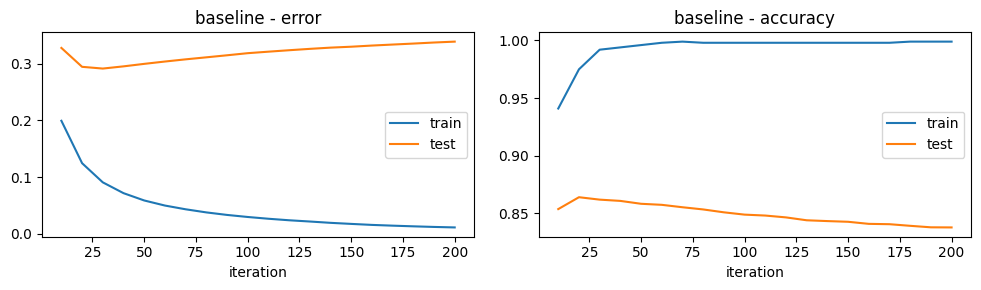

final: train acc 0.999, test acc 0.838;  best test acc 0.864 at iteration 20


In [3]:
log_base = run(alpha=0.005, hidden=40, iterations=200, dropout=False, batch_size=1, report=10)
show(log_base, 'baseline')

Akurasi pelatihan mencapai (hampir) 100%, tetapi akurasi pengujian mencapai puncak lebih awal (sekitar 86% hanya setelah 20 iterasi) dan kemudian perlahan *menurun* menjadi sekitar 84% seiring pelatihan berlanjut:
jaringan menghafal 1.000 gambar pelatihan tersebut. Kesenjangan antara akurasi latih dan akurasi uji adalah gejala khas dari overfitting. *Early stopping* akan menghentikan pelatihan pada iterasi di mana akurasi/error uji mencapai nilai terbaik.

## 2. Dropout


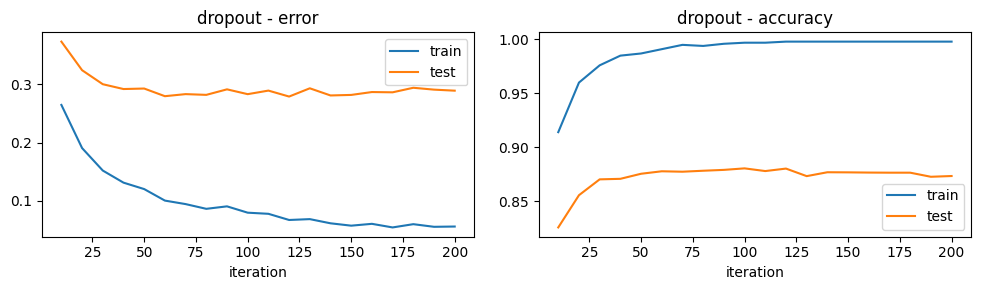

final: train acc 0.998, test acc 0.873;  best test acc 0.880 at iteration 100


In [4]:
log_drop = run(alpha=0.005, hidden=100, iterations=200, dropout=True, batch_size=1, report=10)
show(log_drop, 'dropout')

Dengan dropout, akurasi uji jelas lebih tinggi (sekitar 87% di akhir dan nilai terbaik 88%, dibandingkan sekitar 84% dan 86% tanpa dropout) serta penurunannya jauh lebih sedikit setelah mencapai puncak. Akurasi latih yang ditampilkan di sini diukur *tanpa* dropout, sehingga tetap mencapai sekitar 100%: dropout tidak menghentikan jaringan untuk menyesuaikan diri dengan data latih, melainkan membuat solusi yang ditemukannya dapat menggeneralisasi dengan lebih baik. Dropout mengubah setiap langkah pelatihan menjadi ansambel (ensemble) sub-jaringan yang beragam.

## 3. Mini-batch gradient descent (dengan dropout)


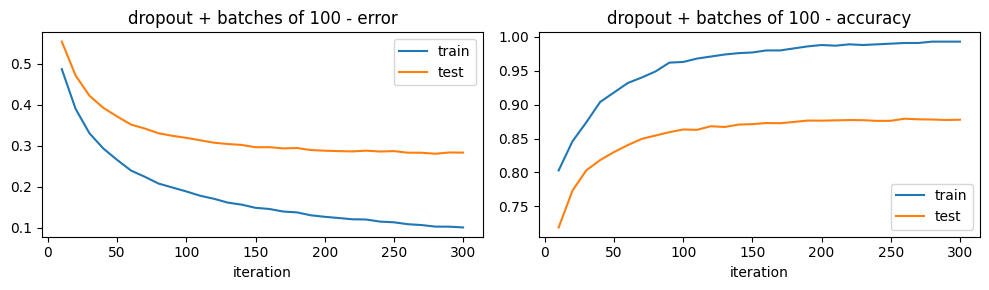

final: train acc 0.993, test acc 0.878;  best test acc 0.879 at iteration 260


In [5]:
# delta dibagi dengan ukuran batch, sehingga alpha yang jauh lebih besar dibanding pembaruan per-contoh sangat tepat
log_batch = run(alpha=0.1, hidden=100, iterations=300, dropout=True, batch_size=100, report=10)
show(log_batch, 'dropout + batches of 100')

Batching merata-ratakan 100 contoh per pembaruan. Metode ini juga jauh lebih cepat pada setiap perulangan data, karena satu perkalian matriks menangani 100 contoh sekaligus alih-alih perulangan loop Python yang memprosesnya satu per satu. Akurasi uji akhir (sekitar 88%) adalah yang tertinggi di antara ketiga metode, dan kurvanya lebih mulus. Karena delta dibagi dengan ukuran batch, learning rate harus jauh lebih besar (0.1 dibanding 0.005 atau 0.001 yang digunakan pada pembaruan satu contoh).

## 4. Perbandingan


In [6]:
import pandas as pd
pd.DataFrame({
    'method': ['no regularization', 'dropout', 'dropout + mini-batch'],
    'train acc': [log_base[-1, 2], log_drop[-1, 2], log_batch[-1, 2]],
    'test acc (final)': [log_base[-1, 4], log_drop[-1, 4], log_batch[-1, 4]],
    'best test acc': [log_base[:, 4].max(), log_drop[:, 4].max(), log_batch[:, 4].max()],
}).round(3)

,method,train acc,test acc (final),best test acc
0,no regularization,0.999,0.838,0.864
1,dropout,0.998,0.873,0.880
2,dropout + mini-batch,0.993,0.878,0.879


## Poin-poin kunci
* Jaringan dapat menghafal data pelatihan (overfit); selalu lakukan evaluasi pada data yang belum pernah dipelajari sebelumnya.
* Early stopping, dropout, dan mini-batching adalah tiga teknik regularisasi/optimasi praktis.
* Dropout hanya diterapkan selama pelatihan: separuh node hidden dinonaktifkan dan sisanya digandakan.
* Mini-batch menghasilkan pelatihan yang lebih mulus dan lebih cepat berkat operasi matriks tervektorisasi.
